## Spikeinterface-Kilosort4 for cMOS    2024.09.20

##### The Notebook called "Maxwell_KS4_Rola20240920_04_GPU_Works" contains the extra codes and old codes all
##### This version 20241029 is the cleaned code with redundant parts excluded 

##### -------------------------------------------------------------------------------------------------------------------------
- This Notebook is designed for using kilosort4 in spikeinterface 
- The first step here is to take care of all steps requested by spikeinterface-kilosort installation guidelines
- Kilosort4¶
-- Python, requires CUDA for GPU acceleration (highly recommended)    
           # I installed CUDA 12.6 (downloaded and installed) Based on GPU of the system NVIDIA GeForce RTX 4080 this new version of CUDA is compatible
           # After installation -> in the Anconda prompt > si_env >> installed the fitting Torch for CUDA -->  pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
           # Then running the python -c "import torch; print(torch.__version__); print(torch.cuda.is_available())"  we get :: 2.4.1+cu121   and True  --> means that now we can use GPU in highly accelerated mode for sorting
           # After that I had to run  conda install ipykernel  >> and then  >> python -m ipykernel install --user --name si_env --display-name "Python (si_env)"   to make Torch readable in the note book
- Url: https://github.com/MouseLand/Kilosort
- Authors: Marius Pachitariu, Shashwat Sridhar, Carsen Stringer

- Installation:
- pip install kilosort==4.0 torch
- For more installation instruction refer to https://github.com/MouseLand/Kilosort 
- as an extra step in the si_env of conda i run the code pip install kilosort==4.0.9   --> to be sure that it is also related to environment  (but the main installation is through the !git clone --branch main https://github.com/MouseLand/Kilosort.git in jupyternotebook below)

- in kilosort3 it says to add path for kilosort but in kilosort4 apparantly it is not necessary
##### -------------------------------------------------------------------------------------------------------------------------

#### ---------------------------------------------------------------------------------------------------------------------
#### This line of code should be run in command prompt or anaconda promt to get the installed version of CUDA  for our case i installed 12.6.68 (after installation of CUDA from NVIDIA)
#### Consider that when running in anaconda --> also activate the environment to be sure that this environment will use GPU 

> conda activate si_env
(si_env) C:\Users\BusskampLab>nvcc --version    # which gives the following infos

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Wed_Aug_14_10:26:51_Pacific_Daylight_Time_2024
Cuda compilation tools, release 12.6, V12.6.68
Build cuda_12.6.r12.6/compiler.34714021_0

#### Here is the comand prompt output for    nvcc --version    :
C:\Users\BusskampLab>nvcc --version
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Wed_Aug_14_10:26:51_Pacific_Daylight_Time_2024
Cuda compilation tools, release 12.6, V12.6.68
Build cuda_12.6.r12.6/compiler.34714021_0
#### ---------------------------------------------------------------------------------------------------------------------

In [1]:
## Check the torch version,   check the CUDA and GPU 
import torch

# Check PyTorch version
print(torch.__version__)

# Check if CUDA is available
print(torch.cuda.is_available())  # Should return True

# Print details of the GPU being used
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
else:
    print("CUDA is not available.")

2.4.1+cu121
True
NVIDIA GeForce RTX 4080


In [2]:
import sys
print(sys.executable)  # Path to the Python interpreter
print(sys.version)     # Python version

c:\Users\BusskampLab\.conda\envs\si_env\python.exe
3.10.13 | packaged by conda-forge | (main, Oct 26 2023, 18:01:37) [MSC v.1935 64 bit (AMD64)]


In [3]:
## List of installed packages 
!pip list

Package                   Version
------------------------- ------------
aiohttp                   3.9.1
aiosignal                 1.3.1
altair                    5.2.0
anyio                     4.1.0
argon2-cffi               23.1.0
argon2-cffi-bindings      21.2.0
arrow                     1.3.0
asciitree                 0.3.3
asttokens                 2.4.1
async-lru                 2.0.4
async-timeout             4.0.3
attrs                     23.1.0
Babel                     2.13.1
beautifulsoup4            4.12.2
bleach                    6.1.0
blosc2                    2.7.1
Brotli                    1.1.0
cached-property           1.5.2
cbor2                     5.5.1
certifi                   2024.8.30
cffi                      1.16.0
charset-normalizer        3.3.2
click                     8.1.7
cloudpickle               3.0.0
colorama                  0.4.6
comm                      0.1.4
contourpy                 1.2.0
cryptography              41.0.7
cuda-python         

In [10]:
# only need to run the first time, then can be commented out
#!git clone https://github.com/MouseLand/Kilosort
#!git clone --branch main https://github.com/MouseLand/Kilosort.git

fatal: destination path 'Kilosort' already exists and is not an empty directory.


In [4]:
#import spikeinterface.toolkit as st

import os
import sys
import loky
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import spikeinterface.full as si
import spikeinterface.extractors as se 
import spikeinterface.widgets as sw
import spikeinterface.sorters as ss
import spikeinterface.comparison as sc
import spikeinterface.postprocessing as spost
import spikeinterface.preprocessing as spre
import spikeinterface.qualitymetrics as sqm
import spikeinterface.curation as scur

from probeinterface import Probe, ProbeGroup
from probeinterface.plotting import plot_probe, plot_probe_group
from probeinterface import generate_multi_columns_probe
from probeinterface import write_probeinterface, read_probeinterface
from probeinterface import write_prb, read_prb

from pathlib import Path

In [5]:
si.__version__

'0.101.0'

In [6]:
#Once cloned, change into the directory where Kilosort is downloaded
%cd Kilosort

d:\MEA_Analysis\Rola_SI_files\Kilosort


In [7]:
#check the available tags (versions) by running
!git tag

1.0
4.0.15
v2.0
v2.0.2
v2.5
v2.5.1
v2.5.2
v3.0
v3.0.1
v3.0.2
v4.0
v4.0.0.1
v4.0.10
v4.0.11
v4.0.12
v4.0.13
v4.0.14
v4.0.15
v4.0.16
v4.0.17
v4.0.2
v4.0.3
v4.0.4
v4.0.5
v4.0.6
v4.0.7
v4.0.8
v4.0.9


In [8]:
import kilosort
print(kilosort.__version__)

4


In [14]:
ss.available_sorters()

['combinato',
 'hdsort',
 'herdingspikes',
 'ironclust',
 'kilosort',
 'kilosort2',
 'kilosort2_5',
 'kilosort3',
 'kilosort4',
 'klusta',
 'mountainsort4',
 'mountainsort5',
 'pykilosort',
 'simple',
 'spykingcircus',
 'spykingcircus2',
 'tridesclous',
 'tridesclous2',
 'waveclus',
 'waveclus_snippets',
 'yass']

In [9]:
ss.installed_sorters()

['kilosort4', 'simple', 'spykingcircus2', 'tridesclous', 'tridesclous2']

In [ ]:
######################-------------------------------#########################-------------------------------

In [9]:
# specify directory of to be sorted data. Data needs to be converted to .raw from .mcd with MC Data Tool
directory = r"D:\MEA_Analysis\Rola_SI_files\ExtraFiles\Ex151_SMS"

# options for parallel processing:
n_workers = 12
chunk_memory = "10M"
tot_memory='10G'

# options for automatic curation/quality control
snr_thresh = 4.5
isi_viol_thresh = 0.2
firing_rate_thresh = 0.1
query = f"snr > {snr_thresh} & isi_violations_rate < {isi_viol_thresh} & firing_rate > {firing_rate_thresh}"

In [ ]:
# get all file information
directory = r"D:\MEA_Analysis\--ExtraFiles\Ex151_SMS"
paths = []
filenames = []
file_count = 0
ext = ('.h5')
for files in os.listdir(directory):
    if files.endswith(ext):
        print(files) 
        paths.append(os.path.join(directory,files))
        filenames.append(files)
        file_count += 1
    else:
        continue
print(paths)
print(filenames)
print(file_count)

20240510_18389_01.raw.h5
20240510_18406_01.raw.h5
20240510_18412_01.raw.h5
20240510_18505_01.raw.h5
20240510_18574_01.raw.h5
20240510_18581_01.raw.h5
20240510_20810_01.raw.h5
20240514_18389_01.raw.h5
20240514_18406_01.raw.h5
20240514_18412_01.raw.h5
20240514_18505_01.raw.h5
20240514_18574_01.raw.h5
20240514_18581_01.raw.h5
20240514_20810_01.raw.h5
20240528_18389_01.raw.h5
20240528_18406_01.raw.h5
20240528_18412_01.raw.h5
20240528_18505_01.raw.h5
20240528_18574_01.raw.h5
20240528_18581_01.raw.h5
20240528_20810_01.raw.h5
['D:\\MEA_Analysis\\Rola_SI_files\\ExtraFiles\\Ex151_SMS\\20240510_18389_01.raw.h5', 'D:\\MEA_Analysis\\Rola_SI_files\\ExtraFiles\\Ex151_SMS\\20240510_18406_01.raw.h5', 'D:\\MEA_Analysis\\Rola_SI_files\\ExtraFiles\\Ex151_SMS\\20240510_18412_01.raw.h5', 'D:\\MEA_Analysis\\Rola_SI_files\\ExtraFiles\\Ex151_SMS\\20240510_18505_01.raw.h5', 'D:\\MEA_Analysis\\Rola_SI_files\\ExtraFiles\\Ex151_SMS\\20240510_18574_01.raw.h5', 'D:\\MEA_Analysis\\Rola_SI_files\\ExtraFiles\\Ex151_SM

# Main_Code 20240923

### Step 01 _ Preprocessing

In [ ]:
##### Step 01 Preprocessing and saving the preprocessed file as .h5 to save space and also to include metadata in the single file

for i in range(file_count):
    recording_file = paths[i]
    recording = se.MaxwellRecordingExtractor(recording_file)
    print(recording)
    # Annotating and applying filters
    recording.annotate(is_filtered=False)
    channel_ids = recording.get_channel_ids()
    fs = recording.get_sampling_frequency()
    num_chan = recording.get_num_channels()
    num_segments = recording.get_num_segments()
    print(f'Channel ids: {channel_ids}')
    print(f'Sampling frequency: {fs}')
    print(f'Number of channels: {num_chan}')
    print(f"Number of segments: {num_segments}")
    recording_f = spre.filter(recording, band=100, btype="highpass", filter_mode="sos", ftype='butter')
    recording_cmr = spre.common_reference(recording_f, reference='global', operator='median')
    
    # Create a folder without .h5 in its name
    output_folder = os.path.join(r"D:\MEA_Analysis\--", f"preprocessed_{filenames[i].replace('.h5', '')}")
    
    # Save the preprocessed recording in that folder
    rec_preprocessed = recording_cmr.save(folder=output_folder, progress_bar=True, n_jobs=n_workers, chunk_memory=chunk_memory)

MaxwellRecordingExtractor: 853 channels - 20.0kHz - 1 segments - 6,001,200 samples 
                           300.06s (5.00 minutes) - uint16 dtype - 9.53 GiB
  file_path: D:\MEA_Analysis\Rola_SI_files\ExtraFiles\Ex151_SMS\20240510_18389_01.raw.h5
Channel ids: ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9' '10' '11' '12' '13' '14' '15'
 '16' '17' '18' '20' '21' '22' '23' '24' '25' '26' '27' '28' '29' '30'
 '31' '32' '33' '34' '35' '36' '37' '38' '39' '40' '41' '42' '43' '44'
 '45' '46' '47' '48' '49' '50' '51' '52' '53' '54' '55' '56' '57' '58'
 '60' '61' '62' '64' '65' '66' '67' '68' '69' '70' '71' '72' '73' '74'
 '76' '77' '78' '79' '81' '82' '83' '84' '85' '86' '87' '88' '89' '90'
 '92' '93' '94' '95' '96' '97' '98' '100' '101' '102' '104' '105' '106'
 '107' '109' '110' '111' '112' '113' '114' '115' '116' '117' '118' '119'
 '120' '121' '122' '125' '126' '127' '128' '129' '130' '132' '133' '134'
 '136' '137' '138' '140' '141' '142' '144' '145' '146' '148' '149' '150'
 '153' '154' '156' '1

write_binary_recording:   0%|          | 0/1024 [00:00<?, ?it/s]

MaxwellRecordingExtractor: 937 channels - 20.0kHz - 1 segments - 6,001,600 samples 
                           300.08s (5.00 minutes) - uint16 dtype - 10.47 GiB
  file_path: D:\MEA_Analysis\Rola_SI_files\ExtraFiles\Ex151_SMS\20240510_18406_01.raw.h5
Channel ids: ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9' '10' '11' '12' '13' '14' '15'
 '16' '17' '18' '19' '20' '21' '22' '23' '24' '25' '26' '27' '28' '29'
 '30' '31' '32' '33' '34' '35' '36' '37' '38' '39' '40' '41' '42' '43'
 '44' '45' '46' '47' '48' '49' '50' '51' '52' '53' '54' '55' '56' '57'
 '58' '59' '60' '61' '62' '63' '64' '65' '66' '67' '68' '69' '70' '71'
 '72' '73' '74' '75' '76' '77' '78' '79' '80' '81' '82' '83' '84' '85'
 '86' '87' '88' '89' '90' '91' '92' '93' '94' '95' '96' '97' '98' '99'
 '100' '101' '102' '103' '104' '105' '106' '107' '108' '109' '110' '111'
 '112' '113' '114' '115' '116' '117' '118' '119' '120' '121' '122' '123'
 '124' '125' '126' '127' '128' '129' '130' '132' '133' '134' '136' '137'
 '138' '140' '142' '1

write_binary_recording:   0%|          | 0/1125 [00:00<?, ?it/s]

MaxwellRecordingExtractor: 507 channels - 20.0kHz - 1 segments - 6,001,800 samples 
                           300.09s (5.00 minutes) - uint16 dtype - 5.67 GiB
  file_path: D:\MEA_Analysis\Rola_SI_files\ExtraFiles\Ex151_SMS\20240510_18412_01.raw.h5
Channel ids: ['1' '5' '6' '7' '8' '10' '13' '15' '16' '17' '19' '20' '21' '23' '24'
 '25' '26' '29' '30' '33' '34' '35' '36' '37' '41' '43' '45' '48' '49'
 '51' '53' '54' '55' '56' '57' '59' '61' '65' '69' '74' '77' '79' '80'
 '81' '85' '90' '93' '95' '98' '100' '105' '107' '109' '122' '128' '139'
 '163' '168' '173' '174' '181' '186' '189' '193' '200' '201' '202' '204'
 '205' '208' '209' '216' '221' '224' '225' '228' '237' '240' '241' '245'
 '248' '252' '306' '318' '330' '334' '346' '350' '358' '386' '397' '401'
 '403' '407' '451' '457' '462' '517' '519' '521' '523' '525' '527' '531'
 '533' '537' '538' '541' '545' '549' '553' '557' '560' '561' '563' '565'
 '569' '571' '572' '573' '577' '580' '581' '582' '583' '585' '589' '591'
 '592' '593' '

...

write_binary_recording:   0%|          | 0/1784 [00:00<?, ?it/s]

MaxwellRecordingExtractor: 311 channels - 20.0kHz - 1 segments - 12,000,800 samples 
                           600.04s (10.00 minutes) - uint16 dtype - 6.95 GiB
  file_path: D:\MEA_Analysis\Rola_SI_files\ExtraFiles\Ex151_SMS\20240528_18581_01.raw.h5
Channel ids: ['1' '5' '7' '8' '9' '11' '17' '23' '25' '28' '29' '34' '35' '37' '41'
 '45' '49' '53' '55' '57' '61' '65' '69' '71' '73' '74' '77' '79' '81'
 '83' '85' '87' '89' '90' '93' '97' '101' '103' '105' '106' '107' '109'
 '112' '113' '117' '121' '125' '127' '129' '133' '137' '145' '149' '153'
 '157' '161' '162' '165' '169' '170' '173' '177' '181' '185' '189' '193'
 '197' '201' '205' '209' '213' '217' '225' '226' '229' '233' '237' '241'
 '242' '245' '249' '251' '253' '261' '265' '273' '277' '281' '293' '296'
 '308' '385' '386' '389' '392' '398' '402' '407' '417' '421' '448' '456'
 '460' '496' '537' '538' '542' '546' '550' '553' '554' '566' '569' '570'
 '572' '578' '580' '582' '584' '588' '589' '594' '596' '598' '604' '605'
 '606' '609

write_binary_recording:   0%|          | 0/747 [00:00<?, ?it/s]

MaxwellRecordingExtractor: 1020 channels - 20.0kHz - 1 segments - 12,001,000 samples 
                           600.05s (10.00 minutes) - uint16 dtype - 22.80 GiB
  file_path: D:\MEA_Analysis\Rola_SI_files\ExtraFiles\Ex151_SMS\20240528_20810_01.raw.h5
Channel ids: ['0' '1' '2' ... '1021' '1022' '1023']
Sampling frequency: 20000.0
Number of channels: 1020
Number of segments: 1
write_binary_recording 
n_jobs=12 - samples_per_chunk=4,901 - chunk_memory=9.53 MiB - total_memory=114.42 MiB - chunk_duration=0.25s (245.05 ms)


write_binary_recording:   0%|          | 0/2449 [00:00<?, ?it/s]

### Step 02 _ Sorting multiple files

In [ ]:
## Sorting multiple files

import os
import torch
import spikeinterface as si
import spikeinterface.sorters as ss

# Define parameters
#n_workers = os.cpu_count() - 1
chunk_memory = "500M"  # Adjust this based on your GPU memory

# Directory where the preprocessed folders are located
base_directory = r"D:\MEA_Analysis\---SI_files"

# Find all folders ending with '.raw'
raw_folders = [folder for folder in os.listdir(base_directory) if folder.endswith('.raw')]
print(f'preprocessed_folders_ready-to-be-sorted_are:', raw_folders)

# Process each .raw folder
for raw_folder in raw_folders:
    preprocessed_folder = os.path.join(base_directory, raw_folder)
    print(f"Processing folder: {preprocessed_folder}")

    # Load extractor
    recording_loaded = si.load_extractor(preprocessed_folder)
    print(f"Loaded recording: {recording_loaded}")

    # Replace '.raw' with output suffix for the results
    output_filename = raw_folder.replace('.raw', '').replace('preprocessed_', '')

    # Output folder will be the same as the base directory, but not inside any subfolder
    output_folder = os.path.join(base_directory, f"results_KS4_{output_filename}")

    # Run Kilosort with GPU processing
    recording_KS = ss.run_sorter(
        'kilosort4', 
        recording_loaded, 
        folder=output_folder, 
        drift_smoothing=False, 
        acg_threshold=0.35, 
        ccg_threshold=0.4, 
        torch_device='cuda:0',  # Ensure it's using GPU
        verbose=True
    )

    # Save the sorted data in the base directory (not inside preprocessed or Kilosort)
    sorting_output_folder = os.path.join(base_directory, f"sorting_KS4_{output_filename}")
    recording_KS_saved = recording_KS.save(folder=sorting_output_folder)
    print(f"Saved sorted data to: {sorting_output_folder}")

    # Clear GPU cache to free up memory
    torch.cuda.empty_cache()

INFO:kilosort.io:========================================
INFO:kilosort.io:Loading recording with SpikeInterface...
INFO:kilosort.io:number of samples: 6001200
INFO:kilosort.io:number of channels: 853
INFO:kilosort.io:numbef of segments: 1
INFO:kilosort.io:sampling rate: 20000.0
INFO:kilosort.io:dtype: int16
INFO:kilosort.io:========================================
INFO:kilosort.run_kilosort: 
INFO:kilosort.run_kilosort:Computing preprocessing variables.
INFO:kilosort.run_kilosort:----------------------------------------


preprocessed_folders_ready-to-be-sorted_are: ['preprocessed_20240510_18389_01.raw', 'preprocessed_20240510_18406_01.raw', 'preprocessed_20240510_18412_01.raw', 'preprocessed_20240510_18505_01.raw', 'preprocessed_20240510_18574_01.raw', 'preprocessed_20240510_18581_01.raw', 'preprocessed_20240510_20810_01.raw', 'preprocessed_20240514_18389_01.raw', 'preprocessed_20240514_18406_01.raw', 'preprocessed_20240514_18412_01.raw', 'preprocessed_20240514_18505_01.raw', 'preprocessed_20240514_18574_01.raw', 'preprocessed_20240514_18581_01.raw', 'preprocessed_20240514_20810_01.raw', 'preprocessed_20240528_18389_01.raw', 'preprocessed_20240528_18406_01.raw', 'preprocessed_20240528_18412_01.raw', 'preprocessed_20240528_18505_01.raw', 'preprocessed_20240528_18574_01.raw', 'preprocessed_20240528_18581_01.raw', 'preprocessed_20240528_20810_01.raw']
Processing folder: D:\MEA_Analysis\Rola_SI_files\preprocessed_20240510_18389_01.raw
Loaded recording: BinaryFolderRecording: 853 channels - 20.0kHz - 1 segm

INFO:kilosort.run_kilosort:Preprocessing filters computed in  1.64s; total  1.64s
INFO:kilosort.run_kilosort: 
INFO:kilosort.run_kilosort:Computing drift correction.
INFO:kilosort.run_kilosort:----------------------------------------
INFO:kilosort.spikedetect:Re-computing universal templates from data.
c:\Users\BusskampLab\.conda\envs\si_env\lib\site-packages\threadpoolctl.py:1010: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
100%|██████████| 101/101 [40:13<00:00, 23.89s/it]
INFO:kilosort.run_kilosort:drift computed in  2419.27s; total  2420.95s
INFO:kilosort.run_kilosort: 
I

kilosort4 run time 5001.40s
Saved sorted data to: D:\MEA_Analysis\Rola_SI_files\sorting_KS4_20240510_18389_01


INFO:kilosort.io:========================================
INFO:kilosort.io:Loading recording with SpikeInterface...
INFO:kilosort.io:number of samples: 6001600
INFO:kilosort.io:number of channels: 937
INFO:kilosort.io:numbef of segments: 1
INFO:kilosort.io:sampling rate: 20000.0
INFO:kilosort.io:dtype: int16
INFO:kilosort.io:========================================
INFO:kilosort.run_kilosort: 
INFO:kilosort.run_kilosort:Computing preprocessing variables.
INFO:kilosort.run_kilosort:----------------------------------------


...

Loaded recording: BinaryFolderRecording: 1020 channels - 20.0kHz - 1 segments - 12,001,000 samples 
                       600.05s (10.00 minutes) - int16 dtype - 22.80 GiB


INFO:kilosort.run_kilosort:Preprocessing filters computed in  1.72s; total  1.72s
INFO:kilosort.run_kilosort: 
INFO:kilosort.run_kilosort:Computing drift correction.
INFO:kilosort.run_kilosort:----------------------------------------
INFO:kilosort.spikedetect:Re-computing universal templates from data.
100%|██████████| 201/201 [5:33:01<00:00, 99.41s/it]   
INFO:kilosort.run_kilosort:drift computed in  19990.32s; total  19992.04s
INFO:kilosort.run_kilosort: 
INFO:kilosort.run_kilosort:Extracting spikes using templates
INFO:kilosort.run_kilosort:----------------------------------------
INFO:kilosort.spikedetect:Re-computing universal templates from data.
100%|██████████| 201/201 [5:32:51<00:00, 99.36s/it]   
INFO:kilosort.run_kilosort:886755 spikes extracted in  19981.06s; total  39973.10s
INFO:kilosort.run_kilosort: 
INFO:kilosort.run_kilosort:First clustering
INFO:kilosort.run_kilosort:----------------------------------------
100%|██████████| 30/30 [03:23<00:00,  6.77s/it]
INFO:kilosor

kilosort4 run time 40959.69s


c:\Users\BusskampLab\.conda\envs\si_env\lib\site-packages\spikeinterface\core\basesorting.py:264: UserWarning: The registered recording will not be persistent on disk, but only available in memory
  warnings.warn("The registered recording will not be persistent on disk, but only available in memory")


Saved sorted data to: D:\MEA_Analysis\Rola_SI_files\sorting_KS4_20240528_20810_01


In [13]:
print(filenames)
print(len(filenames))

['20240510_18389_01.raw.h5', '20240510_18406_01.raw.h5', '20240510_18412_01.raw.h5', '20240510_18505_01.raw.h5', '20240510_18574_01.raw.h5', '20240510_18581_01.raw.h5', '20240510_20810_01.raw.h5', '20240514_18389_01.raw.h5', '20240514_18406_01.raw.h5', '20240514_18412_01.raw.h5', '20240514_18505_01.raw.h5', '20240514_18574_01.raw.h5', '20240514_18581_01.raw.h5', '20240514_20810_01.raw.h5', '20240528_18389_01.raw.h5', '20240528_18406_01.raw.h5', '20240528_18412_01.raw.h5', '20240528_18505_01.raw.h5', '20240528_18574_01.raw.h5', '20240528_18581_01.raw.h5', '20240528_20810_01.raw.h5']
21


### Step 03 _ Export Unit Timeseries

In [ ]:
## Export the timestamps
# Set global job parameters for parallel processing
si.set_global_job_kwargs(n_jobs=15, chunk_duration="1s", progress_bar=True)

# Directory where the preprocessed folders are located
base_directory = r"D:\MEA_Analysis\--_SI_files"

for filename in filenames:
    preprocessed_folder = os.path.join(base_directory, f"preprocessed_{filename.replace('.h5', '')}")
    results_folder = os.path.join(base_directory, f"results_KS4_{filename.replace('.raw.h5', '')}")
    sorting_folder = os.path.join(base_directory, f"sorting_KS4_{filename.replace('.raw.h5', '')}")
    #autocurated_folder = os.path.join(base_directory, f"Autocurated_KS4_{filename.replace('.raw.h5', '')}")  ## Autocur is not necessary 
    #wf_folder = os.path.join(base_directory, f"Waveforms_KS4_{filename.replace('.raw.h5', '')}")             ## wf will be in Analyzer extraction in later steps

    try:
        print(f"Exporting timestamps to CSV for file: {filename.replace('.raw.h5', '')}")
        
        # Load the autocurated sorting data
        #sorting_autocur_loaded = si.load_extractor(autocurated_folder)
        sorting_loaded = si.load_extractor(sorting_folder)   # Autocuration does not work well so I exclude it in this part

        # Get the number of units and collect the spike trains
        n = len(sorting_loaded.get_unit_ids())
        data = {}
        for k in range(n):
            unit_id = sorting_loaded.get_unit_ids()[k]
            data[str(unit_id)] = sorting_loaded.get_unit_spike_train(unit_id)

        # Create a DataFrame from the spike train data
        df = pd.DataFrame.from_dict(data, orient='index').transpose()

        # Generate the output CSV filename
        output_csv_filename = os.path.join(base_directory, f'Noncurated_timestamps_{filename.replace(".raw.h5", "")}.csv')

        # Save the DataFrame to a CSV file in the base directory
        df.to_csv(output_csv_filename)

        print(f"CSV saved at: {output_csv_filename}")

    except Exception as e:
        print(f"An error occurred while exporting timestamps for {filename.replace('.h5', '')}: {e}")
        error_files_csv.append(filename)

Exporting timestamps to CSV for file: 20240510_18389_01
CSV saved at: D:\MEA_Analysis\Rola_SI_files\Noncurated_timestamps_20240510_18389_01.csv
Exporting timestamps to CSV for file: 20240510_18406_01
CSV saved at: D:\MEA_Analysis\Rola_SI_files\Noncurated_timestamps_20240510_18406_01.csv
Exporting timestamps to CSV for file: 20240510_18412_01
CSV saved at: D:\MEA_Analysis\Rola_SI_files\Noncurated_timestamps_20240510_18412_01.csv
Exporting timestamps to CSV for file: 20240510_18505_01
CSV saved at: D:\MEA_Analysis\Rola_SI_files\Noncurated_timestamps_20240510_18505_01.csv
Exporting timestamps to CSV for file: 20240510_18574_01
CSV saved at: D:\MEA_Analysis\Rola_SI_files\Noncurated_timestamps_20240510_18574_01.csv
Exporting timestamps to CSV for file: 20240510_18581_01
CSV saved at: D:\MEA_Analysis\Rola_SI_files\Noncurated_timestamps_20240510_18581_01.csv
Exporting timestamps to CSV for file: 20240510_20810_01
CSV saved at: D:\MEA_Analysis\Rola_SI_files\Noncurated_timestamps_20240510_20810

### Step 04 _ Extract Unit Positions,  Map the Probe-UnitPos  (without saving Analyzer file)

Plotting probe and units for file: 20240510_18389_01
Probe - 853ch - 1shanks


estimate_sparsity:   0%|          | 0/301 [00:00<?, ?it/s]

SortingAnalyzer: 853 channels - 553 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/301 [00:00<?, ?it/s]

20240510_18389_01.raw.h5: CSV export completed successfully.
Probe - 853ch - 1shanks


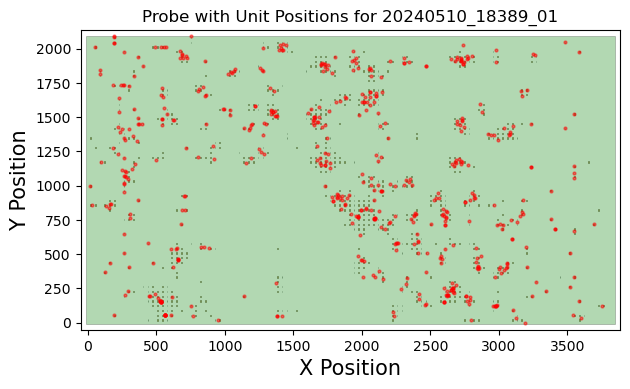

----------------------------------------------------------------
Plotting probe and units for file: 20240510_18406_01
Probe - 937ch - 1shanks


estimate_sparsity:   0%|          | 0/301 [00:00<?, ?it/s]

SortingAnalyzer: 937 channels - 608 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/301 [00:00<?, ?it/s]

20240510_18406_01.raw.h5: CSV export completed successfully.
Probe - 937ch - 1shanks


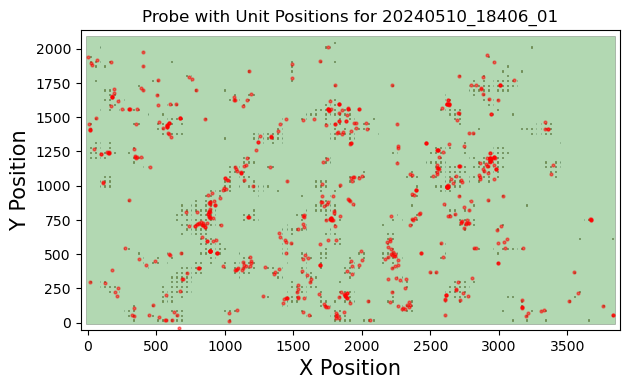

----------------------------------------------------------------
Plotting probe and units for file: 20240510_18412_01
Probe - 507ch - 1shanks


estimate_sparsity:   0%|          | 0/301 [00:00<?, ?it/s]

SortingAnalyzer: 507 channels - 286 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/301 [00:00<?, ?it/s]

20240510_18412_01.raw.h5: CSV export completed successfully.
Probe - 507ch - 1shanks


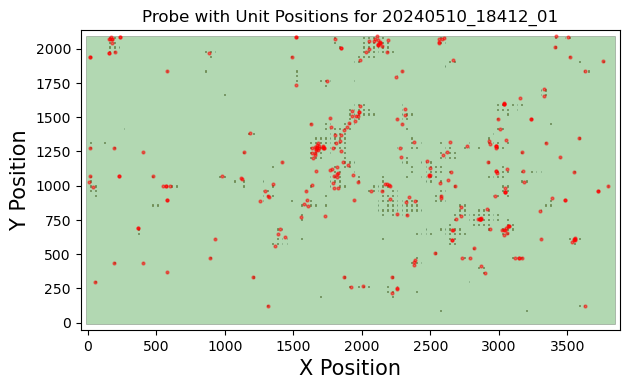

----------------------------------------------------------------
Plotting probe and units for file: 20240510_18505_01
Probe - 1020ch - 1shanks


estimate_sparsity:   0%|          | 0/301 [00:00<?, ?it/s]

SortingAnalyzer: 1020 channels - 668 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/301 [00:00<?, ?it/s]

20240510_18505_01.raw.h5: CSV export completed successfully.
Probe - 1020ch - 1shanks


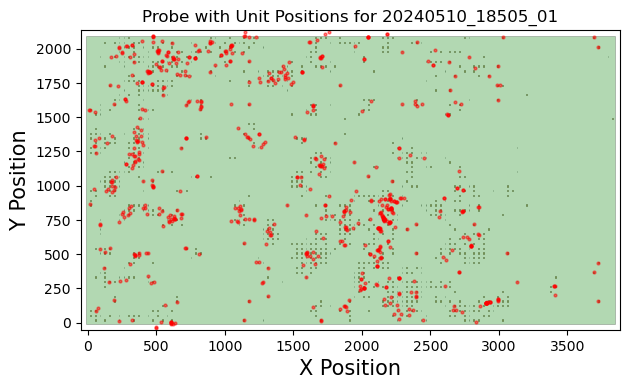

----------------------------------------------------------------
Plotting probe and units for file: 20240510_18574_01
Probe - 486ch - 1shanks


estimate_sparsity:   0%|          | 0/401 [00:00<?, ?it/s]

SortingAnalyzer: 486 channels - 472 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/401 [00:00<?, ?it/s]

20240510_18574_01.raw.h5: CSV export completed successfully.
Probe - 486ch - 1shanks


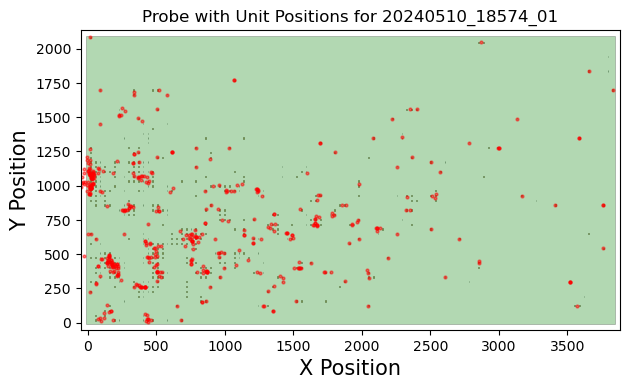

----------------------------------------------------------------
Plotting probe and units for file: 20240510_18581_01
Probe - 561ch - 1shanks


estimate_sparsity:   0%|          | 0/301 [00:00<?, ?it/s]

SortingAnalyzer: 561 channels - 323 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/301 [00:00<?, ?it/s]

20240510_18581_01.raw.h5: CSV export completed successfully.
Probe - 561ch - 1shanks


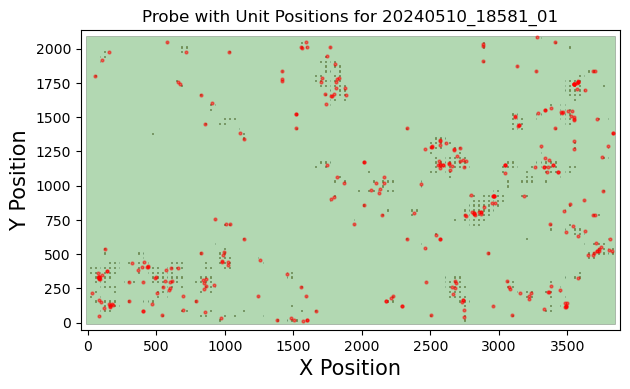

----------------------------------------------------------------
Plotting probe and units for file: 20240510_20810_01
Probe - 1020ch - 1shanks


estimate_sparsity:   0%|          | 0/301 [00:00<?, ?it/s]

SortingAnalyzer: 1020 channels - 666 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/301 [00:00<?, ?it/s]

20240510_20810_01.raw.h5: CSV export completed successfully.
Probe - 1020ch - 1shanks


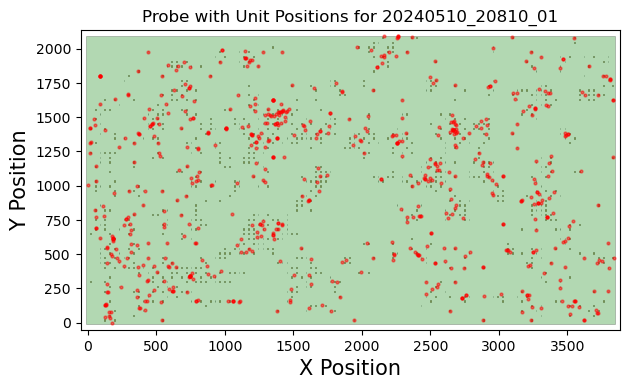

----------------------------------------------------------------
Plotting probe and units for file: 20240514_18389_01
Probe - 994ch - 1shanks


estimate_sparsity:   0%|          | 0/801 [00:00<?, ?it/s]

SortingAnalyzer: 994 channels - 907 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/801 [00:00<?, ?it/s]

20240514_18389_01.raw.h5: CSV export completed successfully.
Probe - 994ch - 1shanks


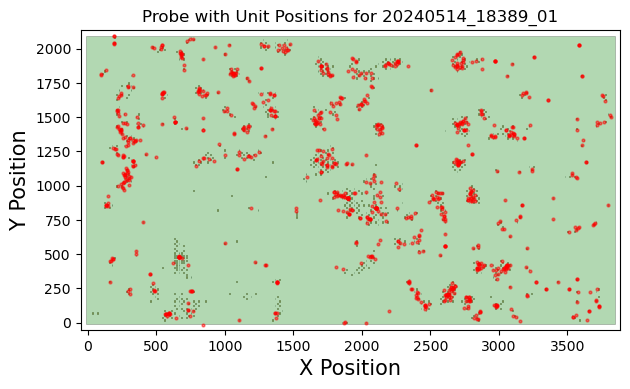

----------------------------------------------------------------
Plotting probe and units for file: 20240514_18406_01
Probe - 876ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 876 channels - 634 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240514_18406_01.raw.h5: CSV export completed successfully.
Probe - 876ch - 1shanks


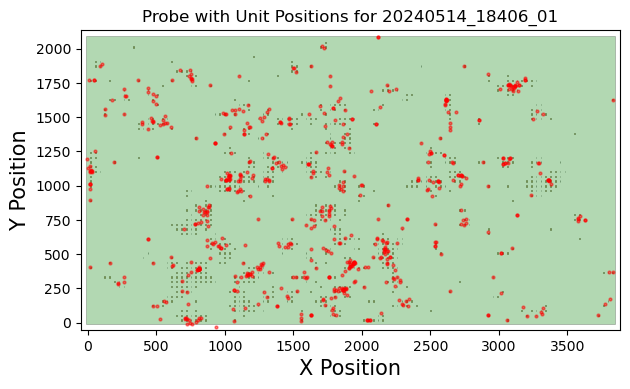

----------------------------------------------------------------
Plotting probe and units for file: 20240514_18412_01
Probe - 781ch - 1shanks


estimate_sparsity:   0%|          | 0/801 [00:00<?, ?it/s]

SortingAnalyzer: 781 channels - 519 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/801 [00:00<?, ?it/s]

20240514_18412_01.raw.h5: CSV export completed successfully.
Probe - 781ch - 1shanks


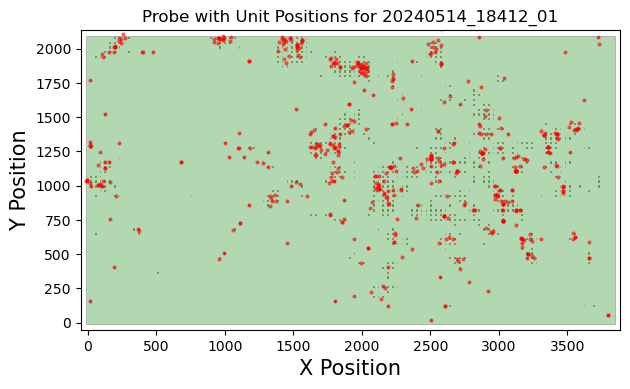

----------------------------------------------------------------
Plotting probe and units for file: 20240514_18505_01
Probe - 671ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 671 channels - 412 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240514_18505_01.raw.h5: CSV export completed successfully.
Probe - 671ch - 1shanks


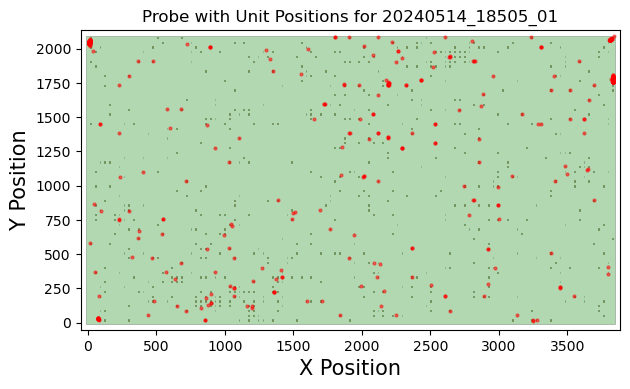

----------------------------------------------------------------
Plotting probe and units for file: 20240514_18574_01
Probe - 588ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 588 channels - 529 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240514_18574_01.raw.h5: CSV export completed successfully.
Probe - 588ch - 1shanks


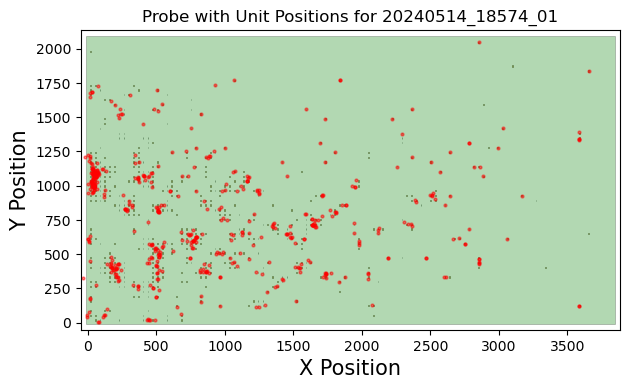

----------------------------------------------------------------
Plotting probe and units for file: 20240514_18581_01
Probe - 747ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 747 channels - 386 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240514_18581_01.raw.h5: CSV export completed successfully.
Probe - 747ch - 1shanks


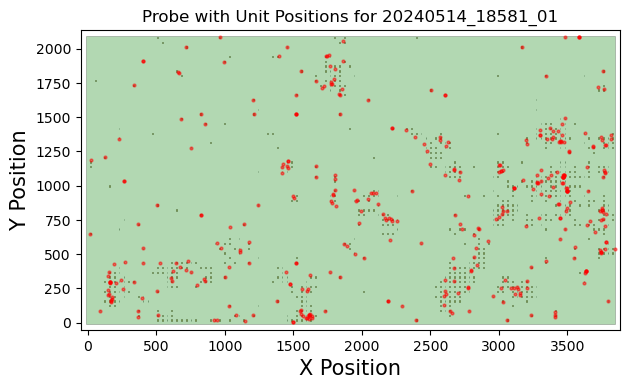

----------------------------------------------------------------
Plotting probe and units for file: 20240514_20810_01
Probe - 873ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 873 channels - 828 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240514_20810_01.raw.h5: CSV export completed successfully.
Probe - 873ch - 1shanks


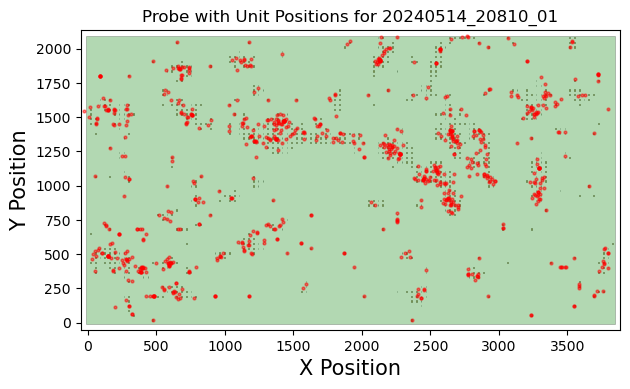

----------------------------------------------------------------
Plotting probe and units for file: 20240528_18389_01
Probe - 248ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 248 channels - 168 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240528_18389_01.raw.h5: CSV export completed successfully.
Probe - 248ch - 1shanks


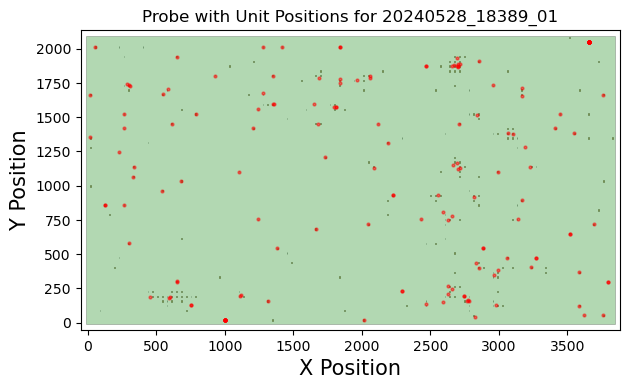

----------------------------------------------------------------
Plotting probe and units for file: 20240528_18406_01
Probe - 954ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 954 channels - 562 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240528_18406_01.raw.h5: CSV export completed successfully.
Probe - 954ch - 1shanks


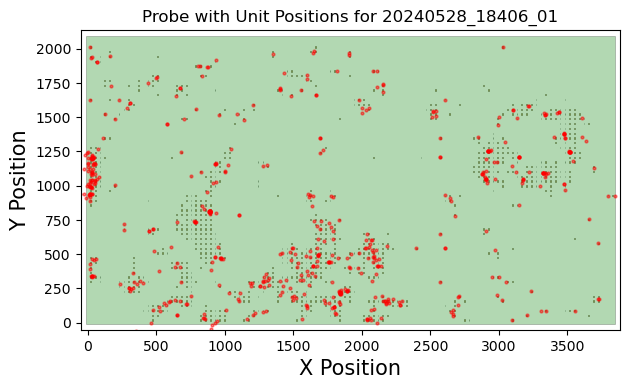

----------------------------------------------------------------
Plotting probe and units for file: 20240528_18412_01
Probe - 519ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 519 channels - 323 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240528_18412_01.raw.h5: CSV export completed successfully.
Probe - 519ch - 1shanks


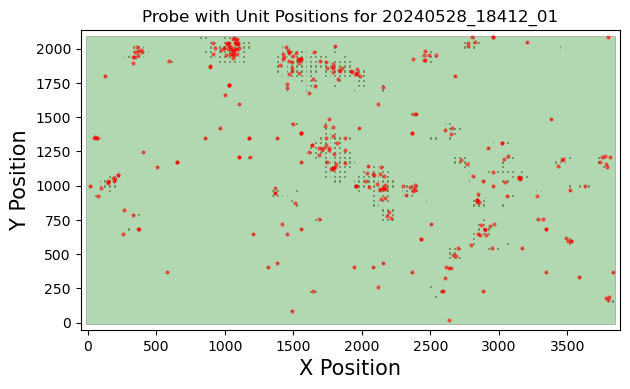

----------------------------------------------------------------
Plotting probe and units for file: 20240528_18505_01
Probe - 1020ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 1020 channels - 1071 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240528_18505_01.raw.h5: CSV export completed successfully.
Probe - 1020ch - 1shanks


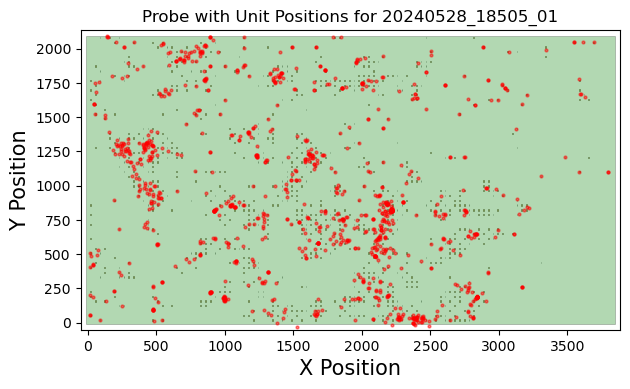

----------------------------------------------------------------
Plotting probe and units for file: 20240528_18574_01
Probe - 743ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 743 channels - 571 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240528_18574_01.raw.h5: CSV export completed successfully.
Probe - 743ch - 1shanks


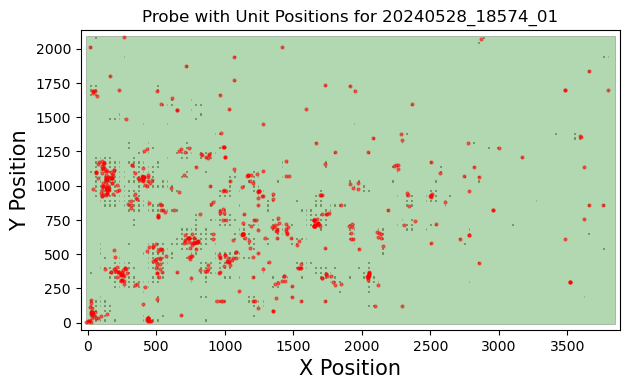

----------------------------------------------------------------
Plotting probe and units for file: 20240528_18581_01
Probe - 311ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 311 channels - 215 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240528_18581_01.raw.h5: CSV export completed successfully.
Probe - 311ch - 1shanks


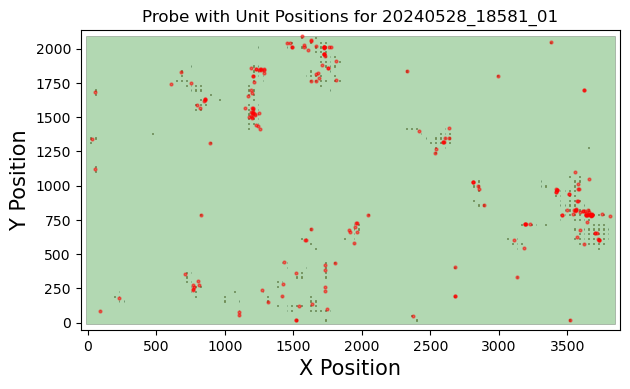

----------------------------------------------------------------
Plotting probe and units for file: 20240528_20810_01
Probe - 1020ch - 1shanks


estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 1020 channels - 892 units - 1 segments - memory - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

20240528_20810_01.raw.h5: CSV export completed successfully.
Probe - 1020ch - 1shanks


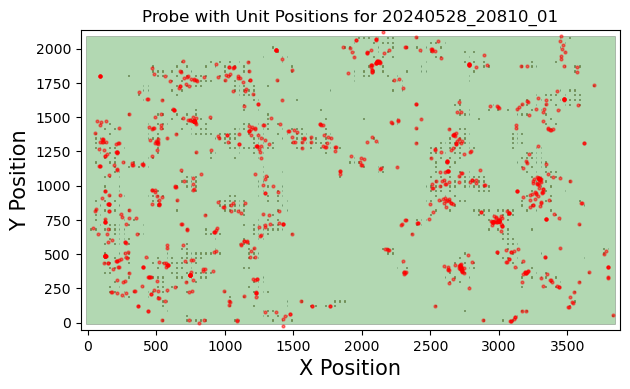

----------------------------------------------------------------


In [ ]:
### Unit Position and probe map   without saving analyzer
# (Here i used directly sorting instead of autocursorting >> because apparantly autocur sorting removes units in upper side of the sensor for all chips !)
# (in this code i use temporary memory for analyzer which are not saved as folder in the drive (but the code for saving is included and deactivated))
# ( to save the analyzer data use the next code which is designed to perform all other steps same but in addition save the analyzer for future data extractions)

from probeinterface.plotting import plot_probe
from spikeinterface import create_sorting_analyzer, load_sorting_analyzer
from spikeinterface.postprocessing import compute_unit_locations

# Set global job parameters for parallel processing
si.set_global_job_kwargs(n_jobs=15, chunk_duration="1s", progress_bar=True)


# Directory where the preprocessed folders are located
base_directory = r"D:\MEA_Analysis\--_SI_files"

for filename in filenames:
    preprocessed_folder = os.path.join(base_directory, f"preprocessed_{filename.replace('.h5', '')}")
    results_folder = os.path.join(base_directory, f"results_KS4_{filename.replace('.raw.h5', '')}")
    sorting_folder = os.path.join(base_directory, f"sorting_KS4_{filename.replace('.raw.h5', '')}")
    #autocurated_folder = os.path.join(base_directory, f"Autocurated_KS4_{filename.replace('.raw.h5', '')}")
    #wf_folder = os.path.join(base_directory, f"Waveforms_KS4_{filename.replace('.raw.h5', '')}")

    try:
        print(f"Plotting probe and units for file: {filename.replace('.raw.h5', '')}")

        # Load the preprocessed data
        recording_loaded = si.load_extractor(preprocessed_folder)
        sorting_loaded = si.load_extractor(sorting_folder)
        #sorting_autocur_loaded = si.load_extractor(autocurated_folder)
        #print(recording_loaded)
        #print(sorting_loaded)
        #print(sorting_autocur_loaded)

        probe = recording_loaded.get_probe()
        print(probe)
        #plot_probe(probe)

        analyzer = create_sorting_analyzer(sorting=sorting_loaded, recording=recording_loaded, format="memory")
        print(analyzer)

        #Or save the analyzer in a folder and call it back
        #analyzer_folder=f"analyzer_KS4_{filename.replace('.raw.h5', '')}"
        #analyzer = create_sorting_analyzer(sorting=sorting_loaded,recording=recording_loaded, format="binary_folder",return_scaled=True, folder=analyzer_folder)
        #print(analyzer)
        # then it can be loaded back
        #analyzer_loaded = load_sorting_analyzer(analyzer_folder)
        #print(analyzer)

        # Compute random spikes first >> this is necessary for performing compute("waveforms")
        analyzer.compute("random_spikes", method="uniform", max_spikes_per_unit=500)

        analyzer.compute("waveforms", ms_before=1.0, ms_after=2.0, n_jobs=15, chunk_duration="1s", progress_bar=True)
        # which is equivalent to this:
        #job_kwargs = dict(n_jobs=8, chunk_duration="1s", progress_bar=True)
        #analyzer.compute("waveforms", ms_before=1.0, ms_after=2.0, **job_kwargs)
        analyzer.compute("templates", operators=["average", "median", "std"])

        #tm = analyzer.compute(input="template_metrics", include_multi_channel_metrics=True)

        unit_loc = compute_unit_locations(analyzer)
        unit_ids = sorting_loaded.get_unit_ids()
        #print(unit_ids, unit_loc)

        # Prepare data for DataFrame
        data = {'unit_id': [], 'x': [], 'y': [], 'z': []}
        for unit_id, position in zip(unit_ids, unit_loc):
            data['unit_id'].append(unit_id)
            data['x'].append(position[0])
            data['y'].append(position[1])
            data['z'].append(position[2])

        
        # Create DataFrame
        df = pd.DataFrame(data)

        # Export unit_positions to the CSV
        df.to_csv(os.path.join(base_directory, f"unitposition_NonCur_{filename.replace('.raw.h5', '')}.csv"), index=False)
        print(f"{filename}: CSV export completed successfully.")

        # Plotting the probe
        probe = recording_loaded.get_probe()
        print(probe)
        plot_probe(probe)

        # Overlaying unit positions
        for i in range(len(unit_ids)):
            # Smaller and transparent red circles
            plt.plot(df['x'][i], df['y'][i], 'ro', markersize=2, alpha=0.5)  # Adjust size and transparency
            # Gray and transparent text
            #plt.text(df['x'][i], df['y'][i], f"{df['unit_id'][i]}", fontsize=3, ha='right', color='gray', alpha=0.5)  # Adjust transparency

        plt.title(f"Probe with Unit Positions for {filename.replace('.raw.h5', '')}")
        plt.xlabel("X Position")
        plt.ylabel("Y Position")

        # Save the plot as a PDF with tight layout
        plt.tight_layout()
        plt.savefig(f'probe_unitpos_{filename.replace(".raw.h5", "")}_noAnot.pdf', format='pdf')
        plt.show()

    except Exception as e:
        print(f"An error occurred while exporting timestamps for {filename.replace('.h5', '')}: {e}")
        error_files_csv.append(filename)

    print('----------------------------------------------------------------')

### Step 05 _ Extract Unit Positions,  Map the Probe-UnitPos  (with saving Analyzer file)

In [ ]:
### Unit Position and probe map   with saving analyzer
# (Here i used directly sorting instead of autocursorting >> because apparantly autocur sorting removes units in upper side of the sensor for all chips !)
# (in this code i save the analyzer that can be loaded and used now or later (this might be useful in case you want to extract further variables in later time points)


from probeinterface.plotting import plot_probe
from spikeinterface import create_sorting_analyzer, load_sorting_analyzer
from spikeinterface.postprocessing import compute_unit_locations

# Set global job parameters for parallel processing
si.set_global_job_kwargs(n_jobs=15, chunk_duration="1s", progress_bar=True)


# Directory where the preprocessed folders are located
base_directory = r"D:\MEA_Analysis\--_SI_files"

for filename in filenames:
    preprocessed_folder = os.path.join(base_directory, f"preprocessed_{filename.replace('.h5', '')}")
    results_folder = os.path.join(base_directory, f"results_KS4_{filename.replace('.raw.h5', '')}")
    sorting_folder = os.path.join(base_directory, f"sorting_KS4_{filename.replace('.raw.h5', '')}")
    #autocurated_folder = os.path.join(base_directory, f"Autocurated_KS4_{filename.replace('.raw.h5', '')}")
    #wf_folder = os.path.join(base_directory, f"Waveforms_KS4_{filename.replace('.raw.h5', '')}")

    try:
        print(f"Plotting probe and units for file: {filename.replace('.raw.h5', '')}")

        # Load the preprocessed data
        recording_loaded = si.load_extractor(preprocessed_folder)
        sorting_loaded = si.load_extractor(sorting_folder)
        #sorting_autocur_loaded = si.load_extractor(autocurated_folder)
        #print(recording_loaded)
        #print(sorting_loaded)
        #print(sorting_autocur_loaded)

        probe = recording_loaded.get_probe()
        print(probe)
        #plot_probe(probe)

        # For temporary memory saved usage of the analyzer use this line of the code (analyzer will not save but it will work to extract and compute unit positions)
        #analyzer = create_sorting_analyzer(sorting=sorting_loaded, recording=recording_loaded, format="memory")
        #print(analyzer)

        #Or save the analyzer in a folder and call it back
        analyzer_folder=os.path.join(base_directory,f"analyzer_KS4_{filename.replace('.raw.h5', '')}_2")
        analyzer = create_sorting_analyzer(sorting=sorting_loaded,recording=recording_loaded, format="binary_folder",return_scaled=True, folder=analyzer_folder)
        print(analyzer)
        # then it can be loaded back
        analyzer_loaded = load_sorting_analyzer(analyzer_folder)
        print(analyzer)

        # Compute random spikes first >> this is necessary for performing compute("waveforms")
        #analyzer.compute("random_spikes", method="uniform", max_spikes_per_unit=500)
        analyzer_loaded.compute("random_spikes", method="uniform", max_spikes_per_unit=500)

        #analyzer.compute("waveforms", ms_before=1.0, ms_after=2.0, n_jobs=15, chunk_duration="1s", progress_bar=True)
        analyzer_loaded.compute("waveforms", ms_before=1.0, ms_after=2.0, n_jobs=15, chunk_duration="1s", progress_bar=True)
        # which is equivalent to this:
        #job_kwargs = dict(n_jobs=8, chunk_duration="1s", progress_bar=True)
        #analyzer.compute("waveforms", ms_before=1.0, ms_after=2.0, **job_kwargs)

        #analyzer.compute("templates", operators=["average", "median", "std"])
        analyzer_loaded.compute("templates", operators=["average", "median", "std"])

        #tm = analyzer_loaded.compute(input="template_metrics", include_multi_channel_metrics=True)

        unit_loc = compute_unit_locations(analyzer_loaded)
        unit_ids = sorting_loaded.get_unit_ids()
        print(unit_ids, unit_loc)

        # Prepare data for DataFrame
        data = {'unit_id': [], 'x': [], 'y': [], 'z': []}
        for unit_id, position in zip(unit_ids, unit_loc):
            data['unit_id'].append(unit_id)
            data['x'].append(position[0])
            data['y'].append(position[1])
            data['z'].append(position[2])

        
        # Create DataFrame
        df = pd.DataFrame(data)

        # Export unit_positions to the CSV
        df.to_csv(os.path.join(base_directory, f"unitposition_NonCur2_{filename.replace('.raw.h5', '')}.csv"), index=False)
        print(f"{filename}: CSV export completed successfully.")

        # Plotting the probe
        #probe = recording_loaded.get_probe()
        #print(probe)
        #plot_probe(probe)

        # Overlaying unit positions
        #for i in range(len(unit_ids)):
            # Smaller and transparent red circles
            #plt.plot(df['x'][i], df['y'][i], 'ro', markersize=2, alpha=0.5)  # Adjust size and transparency
            # Gray and transparent text
            #plt.text(df['x'][i], df['y'][i], f"{df['unit_id'][i]}", fontsize=3, ha='right', color='gray', alpha=0.5)  # Adjust transparency

        #plt.title(f"Probe with Unit Positions for {filename.replace('.raw.h5', '')}")
        #plt.xlabel("X Position")
        #plt.ylabel("Y Position")

        # Save the plot as a PDF with tight layout
        #plt.tight_layout()
        #plt.savefig(f'probe_unitpos_{filename.replace(".raw.h5", "")}_noAnot.pdf', format='pdf')
        #plt.show()

    except Exception as e:
        print(f"An error occurred while exporting timestamps for {filename.replace('.h5', '')}: {e}")
        error_files_csv.append(filename)

    print('----------------------------------------------------------------')

Plotting probe and units for file: 20240510_18389_01
Probe - 853ch - 1shanks


estimate_sparsity:   0%|          | 0/301 [00:00<?, ?it/s]

SortingAnalyzer: 853 channels - 553 units - 1 segments - binary_folder - sparse - has recording
Loaded 0 extensions: 
SortingAnalyzer: 853 channels - 553 units - 1 segments - binary_folder - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/301 [00:00<?, ?it/s]

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233
 234 235 236 237 238 239 240 241 242 243 244 245 24

...

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214] [[1.10247010e+03 5.13627770e+01 5.60245826e+00]
 [1.52250000e+03 1.75000000e+01 2.00000000e+01]
 [1.52250000e+03 1.75031471e+01

estimate_sparsity:   0%|          | 0/601 [00:00<?, ?it/s]

SortingAnalyzer: 1020 channels - 892 units - 1 segments - binary_folder - sparse - has recording
Loaded 0 extensions: 
SortingAnalyzer: 1020 channels - 892 units - 1 segments - binary_folder - sparse - has recording
Loaded 0 extensions: 


compute_waveforms:   0%|          | 0/601 [00:00<?, ?it/s]

[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
 162 163 164 165 166 167 168 169 170 171 172 173 174 175 176 177 178 179
 180 181 182 183 184 185 186 187 188 189 190 191 192 193 194 195 196 197
 198 199 200 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215
 216 217 218 219 220 221 222 223 224 225 226 227 228 229 230 231 232 233
 234 235 236 237 238 239 240 241 242 243 244 245 24